# 07 · Predicción de series temporales con redes neuronales

El módulo 06 explicó cómo recuerda una red recurrente y mostró una primera predicción sobre una señal sintética. Predecir de verdad es más duro: los datos son ruidosos, una línea base de una sola línea resulta sorprendentemente difícil de superar, y un modelo de gradient boosting que entrena en dos segundos te espera en la meta. Este módulo somete a los modelos neuronales a esa prueba en **dos problemas de tipo real con ganadores opuestos**, y luego pregunta si un modelo que *nunca se entrenó con tus datos* puede igualarlos.

> La versión amplia, método por método, de esta comparación (SARIMA, Prophet, Keras y todo lo demás) es el [módulo de series temporales de Python 1001](https://python.academy.forwardforecasting.eu/es/12-prevision-de-series-temporales/). Este notebook copia sus dos problemas y su carga de datos, deja lo que no es neuronal y profundiza en el lado neuronal, así que los números son comparables (las diferencias se explican donde aparecen).

| Sección | Idea | Experimento |
|---|---|---|
| 1 | cómo plantear y evaluar predicciones neuronales | predicciones multi-horizonte directas desde orígenes móviles |
| 2-3 | líneas base a superar | estacional ingenuo y XGBoost (extreme gradient boosting) sobre la demanda horaria de bicicletas compartidas |
| 4 | redes recurrentes y de atención con datos reales | una GRU (gated recurrent unit, unidad recurrente con puertas), una LSTM (long short-term memory, memoria a corto y largo plazo) y un Transformer por parches en PyTorch |
| 5-6 | un segundo problema donde la memoria importa | caudal de un río impulsado por la lluvia: líneas base, y luego GRU y LSTM codificador-decodificador y un Transformer por parches |
| 7 | modelo de base en cero disparos | TimesFM 3 (un Transformer preentrenado) predice ambos problemas sin ningún entrenamiento |
| 8 | incertidumbre | pérdida cuantílica (pinball): una red que predice una banda, no una línea, y cómo se compara su banda con la del modelo de base |
| 9 | guía de decisión | cuándo compensa cada modelo neuronal |

**Contenido:** 1. Planteamiento y evaluación, 2. Datos del problema 1, 3. Líneas base, 4. Redes neuronales en el problema 1, 5. Datos y líneas base del problema 2, 6. Redes neuronales en el problema 2, 7. Modelo de base en cero disparos, 8. Predicción probabilística, 9. Guía de decisión, Ideas clave, Ejercicios, Referencias.

**Se apoya en**

| Módulo | Qué aportó |
|---|---|
| [01 · La neurona](https://neural-networks.academy.forwardforecasting.eu/es/01-la-neurona-artificial/) y [02 · Retropropagación](https://neural-networks.academy.forwardforecasting.eu/es/02-retropropagacion/) | capas, pérdida, descenso del gradiente |
| [03 · Entrenar bien](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) | normalización, parada temprana, Adam |
| [06 · Redes recurrentes](https://neural-networks.academy.forwardforecasting.eu/es/06-redes-recurrentes/) | el bucle GRU/LSTM, estado oculto, predicciones multi-horizonte directas, la línea base estacional ingenua. No se repite aquí. |
| [09 · El Transformer](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/) | autoatención y bloques codificadores, usados en la sección 4 sobre parches de una serie |

Todo es PyTorch y funciona en una CPU. Los dos conjuntos de datos son pequeños; la única descarga que no lo es son los 1,3 GB del modelo de base, que se guardan tras la primera ejecución, y sus predicciones también se guardan, de modo que una segunda ejecución se ahorra ese cálculo. En un entorno limpio de 2 CPU el notebook completo tardó unos 3 minutos con los pronósticos ya en caché; la primera vez, calcularlos añade unos minutos más.

**Dónde se diferencia este juguete de los sistemas reales:** los servicios reales de predicción entrenan con miles de series y años de datos, ajustan cada modelo y lo reentrenan periódicamente. Aquí cada red es pequeña, se entrena unos minutos con uno o dos conjuntos de datos, así que lee *la clasificación y las razones*, no el tercer decimal.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks/es/07_prevision_de_series_temporales_con_redes_neuronales.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: unos 3 minutos, con un pico de memoria de unos 1,6 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [1]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'xgboost': 'xgboost',
    'timesfm3': 'timesfm @ git+https://github.com/google-research/timesfm.git@e51928e27119cb17bebc005be2696b75e0a9e688',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

Entorno: Python 3.12.3 | local | CPUs: 32


## 1. Planteamiento y evaluación

**Predicción directa multi-horizonte.** En cada origen de predicción (un momento en que hay que emitir una predicción, por ejemplo cada medianoche) el modelo ve el pasado y devuelve de una vez los $H$ valores futuros, en lugar de realimentar sus propias predicciones (la forma recursiva, que el módulo 06 mostró que acumula errores).

**Entradas futuras conocidas.** Algunas entradas se conocen cuando se emite la predicción: el calendario, un pronóstico del tiempo o de lluvia. Se entregan al modelo como una segunda entrada junto al historial. Las redes neuronales lo manejan de forma natural: un codificador recurrente lee el historial, y el futuro conocido se concatena (problema 1) o se alimenta paso a paso a un decodificador (problema 2).

**Evaluación honesta.**
- Divide por **tiempo**, nunca al azar: entrena con el pasado, prueba con el futuro.
- Predice desde muchos **orígenes móviles** del periodo de prueba, como se usaría el modelo.
- Informa siempre de una **línea base**: una red que no supera al estacional ingenuo no es útil.
- Informa del error en las unidades que importan (bicicletas por hora, unidades de caudal) y, donde importe, del error en los **eventos raros y grandes**.

Notación: $L$ es el número de horas pasadas que recibe el modelo, $H$ el número de horas a predecir, MAE (mean absolute error, error absoluto medio) el promedio de $|\text{predicción} - \text{real}|$, y RMSE (root mean squared error, raíz del error cuadrático medio) la raíz del promedio de los errores al cuadrado, que castiga más los errores grandes.

## 2. Problema 1: demanda horaria de bicicletas compartidas

Dos años (2011-2012) de alquileres por hora de Capital Bikeshare, en Washington D. C., con el tiempo atmosférico y el calendario: el conjunto de datos *Bike Sharing* de la UCI (University of California Irvine) ([Fanaee-T y Gama, 2013](https://doi.org/10.1007/s13748-013-0040-3); [página del conjunto](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), licencia CC BY 4.0, que solo exige atribución), descargado de [OpenML](https://www.openml.org/d/42712) y guardado en caché por scikit-learn. La copia de OpenML elimina la columna de fecha; las filas están en orden temporal, así que las marcas de tiempo se reconstruyen a partir del año, mes, día de la semana y hora, y se rellenan 165 horas faltantes (sin alquileres registrados). Es el mismo código de carga que el módulo de Python 1001.

**Tarea:** cada medianoche, predecir los 24 recuentos horarios del día siguiente. Entrenar con enero de 2011 a septiembre de 2012 y probar con los 92 días de octubre a diciembre de 2012. Modelamos $\log(1 + \text{recuento})$ para que los errores de madrugada y de hora punta cuenten en proporción, y puntuamos en bicicletas por hora.

(17544, 11) 2011-01-01 00:00:00 -> 2012-12-31 23:00:00


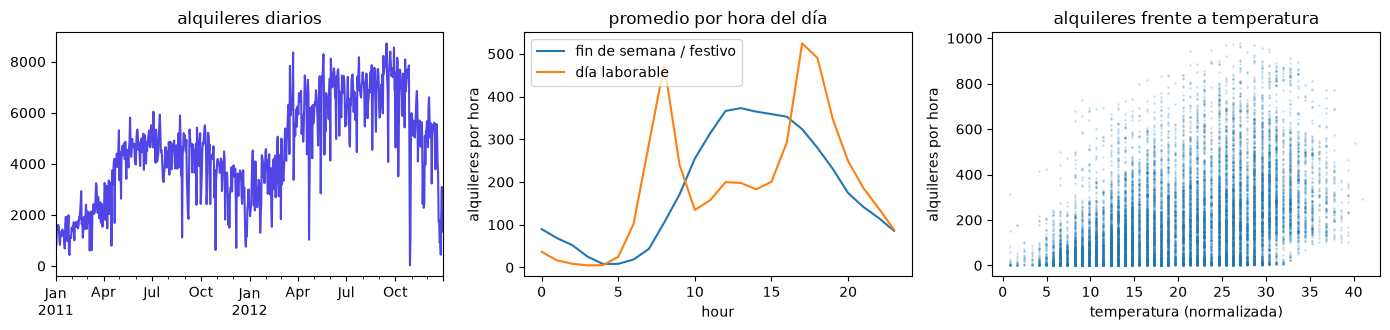

In [2]:
import os, time, warnings, logging
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import fetch_openml

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(2)
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())

try:
    raw = fetch_openml(data_id=42712, as_frame=True, parser="auto").frame
except TypeError:      # algunas parejas de versiones de pandas y scikit-learn rompen el lector rápido de ARFF; el de Python puro es más lento pero siempre funciona
    raw = fetch_openml(data_id=42712, as_frame=True, parser="liac-arff").frame
# un día nuevo empieza cuando la hora baja o cambia el día de la semana
day, days, prev_h, prev_wd = 0, [], None, None
for h, wd in zip(raw["hour"].astype(int), raw["weekday"].astype(str)):
    if prev_h is not None and (h <= prev_h or wd != prev_wd):
        day += 1
    days.append(day); prev_h, prev_wd = h, wd
raw.index = pd.Timestamp("2011-01-01") + pd.to_timedelta(days, "D") + pd.to_timedelta(raw["hour"].astype(int), "h")
assert (raw.index.dayofweek == (raw["weekday"].astype(int) + 6) % 7).all()     # las fechas reconstruidas coinciden con los días de la semana

WEATHER = ["temp", "feel_temp", "humidity", "windspeed"]
bike = raw.reindex(pd.date_range(raw.index.min(), raw.index.max(), freq="h"))
bike["count"] = bike["count"].fillna(0)
for c in WEATHER + ["weather", "holiday", "workingday"]:
    bike[c] = bike[c].ffill()
bike = pd.DataFrame({
    "count": bike["count"].astype(float),
    **{c: bike[c].astype(float) for c in WEATHER},
    "weather": bike["weather"].astype(str).astype("category").cat.codes,
    "holiday": bike["holiday"].astype(str).isin(["True", "1"]).astype(int),
    "workingday": bike["workingday"].astype(str).isin(["True", "1"]).astype(int),
}, index=bike.index)
bike["hour"], bike["dow"], bike["month"] = bike.index.hour, bike.index.dayofweek, bike.index.month
print(bike.shape, bike.index.min(), "->", bike.index.max())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
bike["count"].resample("D").sum().plot(ax=ax[0], title="alquileres diarios", color="#4f46e5"); ax[0].set_xlabel("")
for wd, g in bike.groupby("workingday"):
    g.groupby("hour")["count"].mean().plot(ax=ax[1], label="día laborable" if wd else "fin de semana / festivo")
ax[1].legend(); ax[1].set_title("promedio por hora del día"); ax[1].set_ylabel("alquileres por hora")
ax[2].scatter(bike["temp"], bike["count"], s=1, alpha=.15); ax[2].set_xlabel("temperatura (normalizada)")
ax[2].set_ylabel("alquileres por hora"); ax[2].set_title("alquileres frente a temperatura")
plt.tight_layout(); plt.show()

In [3]:
bike["y"] = np.log1p(bike["count"])
TEST_START = pd.Timestamp("2012-10-01")
test_days = pd.date_range(TEST_START, bike.index.max().normalize(), freq="D")
y_true = bike.loc[bike.index >= TEST_START, "count"].to_numpy()

results, forecasts = {}, {}
def score(name, pred_log, seconds, params=None):
    pred = np.clip(np.expm1(np.asarray(pred_log)), 0, None)
    forecasts[name] = pred
    results[name] = {"MAE (bikes/h)": np.mean(np.abs(pred - y_true)),
                     "RMSE (bikes/h)": np.sqrt(np.mean((pred - y_true) ** 2)),
                     "seconds": seconds, "parameters": params}
    print(f"{name:<26} MAE {results[name]['MAE (bikes/h)']:6.1f}   RMSE {results[name]['RMSE (bikes/h)']:6.1f}   ({seconds:.0f} s)")
print(f"{len(test_days)} test days, {len(y_true):,} hours")

92 test days, 2,208 hours


## 3. Las líneas base a superar: estacional ingenuo y XGBoost

Dos modelos que no son redes neuronales fijan el listón, y toda red de abajo debe compararse con ambos.

- **Estacional ingenuo**: mañana a las 8:00 se parecerá al mismo día de la semana pasada a las 8:00. Una línea, sin ajuste. Una red que pierde contra él está rota o es inútil.
- **XGBoost** ([Chen y Guestrin, 2016](https://arxiv.org/abs/1603.02754)): árboles de decisión con gradient boosting sobre una tabla de características: calendario, tiempo atmosférico y **retardos conocidos a medianoche** (la misma hora de ayer, de hace dos días, de la semana pasada, y el promedio de ayer). Un solo modelo predice directamente cada hora del día.

SARIMA (seasonal autoregressive integrated moving average), Prophet y los demás métodos clásicos se comparan en este mismo problema en el [módulo de Python 1001](https://python.academy.forwardforecasting.eu/es/12-prevision-de-series-temporales/); con estos datos ambos pierden contra el estacional ingenuo, y por eso no se repiten aquí.

In [4]:
t0 = time.perf_counter()
score("Seasonal naive (7 d)", bike["y"].shift(168).loc[bike.index >= TEST_START], time.perf_counter() - t0, 0)

import xgboost as xgb
feat = bike.copy()
feat["lag24"], feat["lag48"], feat["lag168"] = feat["y"].shift(24), feat["y"].shift(48), feat["y"].shift(168)
feat["prev_day_mean"] = feat["y"].shift(24).rolling(24).mean()     # termina como muy tarde en la medianoche de la predicción
feat["trend"] = np.arange(len(feat))
FEATURES = ["hour", "dow", "month", "workingday", "holiday", "weather", *WEATHER,
            "lag24", "lag48", "lag168", "prev_day_mean", "trend"]
tr_rows = feat.loc[feat.index < TEST_START].dropna()
te_rows = feat.loc[feat.index >= TEST_START]

t0 = time.perf_counter()
xgb_model = xgb.XGBRegressor(n_estimators=800, max_depth=7, learning_rate=0.03, subsample=0.8,
                             colsample_bytree=0.8, n_jobs=2, random_state=0)
xgb_model.fit(tr_rows[FEATURES], tr_rows["y"])
score("XGBoost", xgb_model.predict(te_rows[FEATURES]), time.perf_counter() - t0, "800 trees")

Seasonal naive (7 d)       MAE   75.9   RMSE  129.8   (0 s)


XGBoost                    MAE   44.6   RMSE   71.0   (1 s)


## 4. Redes neuronales en el problema 1: GRU, LSTM y un Transformer por parches

Los modelos de secuencia reciben el historial en bruto en lugar de retardos hechos a mano: los últimos **7 días** (168 horas) de demanda, tiempo atmosférico y calendario, más el tiempo y el calendario de las **24 horas a predecir**, y devuelven los 24 valores de una vez. El calendario entra como seno y coseno de la hora y del día de la semana, para que las 23:00 y las 00:00 sean vecinas. Todo se normaliza solo con estadísticas de entrenamiento. El entrenamiento usa una de cada cuatro horas del periodo de entrenamiento como origen de predicción (unos 3.600 ejemplos); las últimas cuatro semanas de entrenamiento se reservan para detener el entrenamiento en la mejor época (parada temprana, módulo 03).

Tres arquitecturas comparten un bucle de entrenamiento y una interfaz `model(past, future_covariates)`:

- **GRU** y **LSTM** (módulo 06): un codificador recurrente lee la semana; su estado oculto final se concatena con las covariables del día siguiente y una pequeña cabeza feed-forward devuelve los 24 valores.
- **Transformer por parches**, la idea de PatchTST ([Nie et al., 2023](https://arxiv.org/abs/2211.14730)): cortar la serie en **parches** (aquí un parche por día, 24 horas de todas las características) y tratar cada parche como un token. La atención trabaja entonces sobre 7 tokens en lugar de 168 horas, lo que es mucho más barato y fue la clave para que los Transformers funcionaran en predicción. El Transformer de aquí es el bloque codificador del módulo 09 con posiciones aprendidas.

In [5]:
SEQ_IN = ["y", "temp", "humidity", "windspeed", "workingday", "holiday"]
FUT_IN = ["temp", "humidity", "windspeed", "workingday", "holiday"]
L, H = 168, 24
arr = bike.assign(h_sin=np.sin(2 * np.pi * bike["hour"] / 24), h_cos=np.cos(2 * np.pi * bike["hour"] / 24),
                  d_sin=np.sin(2 * np.pi * bike["dow"] / 7), d_cos=np.cos(2 * np.pi * bike["dow"] / 7))
CAL = ["h_sin", "h_cos", "d_sin", "d_cos"]
past = arr[SEQ_IN + CAL].to_numpy(np.float32)
future = arr[FUT_IN + CAL].to_numpy(np.float32)
target = arr["y"].to_numpy(np.float32)
n_train_rows = arr.index.get_loc(TEST_START)
mu, sd = past[:n_train_rows].mean(0), past[:n_train_rows].std(0) + 1e-6
fmu, fsd = future[:n_train_rows].mean(0), future[:n_train_rows].std(0) + 1e-6
past_n, fut_n = (past - mu) / sd, (future - fmu) / fsd
y_mu, y_sd = mu[0], sd[0]

def make(origins):
    X = np.stack([past_n[o - L:o] for o in origins])
    F = np.stack([fut_n[o:o + H] for o in origins])
    Y = np.stack([(target[o:o + H] - y_mu) / y_sd for o in origins])
    return X, F, Y

test_o = [arr.index.get_loc(d) for d in test_days]
val_start = arr.index.get_loc(TEST_START - pd.Timedelta(weeks=4))
train_o = list(range(L, val_start - H, 4))
val_o = [arr.index.get_loc(d) for d in pd.date_range(TEST_START - pd.Timedelta(weeks=4), TEST_START - pd.Timedelta(days=1), freq="D")]
train1, val1, test1 = make(train_o), make(val_o), make(test_o)
print("train", train1[0].shape, "validation", val1[0].shape, "test", test1[0].shape)
to_log = lambda p: p.reshape(-1) * y_sd + y_mu

train (3618, 168, 10) validation (28, 168, 10) test (92, 168, 10)


In [6]:
def fit(model, train, val, test, loss_fn=nn.functional.mse_loss, epochs=25, lr=2e-3, batch=128, patience=4, seed=0):
    '''One training loop for every network in this notebook: Adam, early stopping on the validation loss,
    restore the best epoch, predict the test windows. Returns (test predictions, epochs run, seconds).'''
    torch.manual_seed(seed); t0 = time.perf_counter()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Xt, Ft, Yt = map(torch.tensor, train); Xv, Fv, Yv = map(torch.tensor, val)
    best, best_state, bad = np.inf, None, 0
    for ep in range(epochs):
        model.train()
        for i in torch.randperm(len(Xt)).split(batch):
            opt.zero_grad(); loss_fn(model(Xt[i], Ft[i]), Yt[i]).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = loss_fn(model(Xv, Fv), Yv).item()
        if v < best - 1e-4:
            best, best_state, bad = v, {k: x.clone() for k, x in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        pred = model(torch.tensor(test[0]), torch.tensor(test[1])).numpy()
    return pred, ep + 1, time.perf_counter() - t0

class RNNForecaster(nn.Module):
    '''Recurrent encoder reads the past week; a small head combines its final state with the next day's covariates.'''
    def __init__(self, kind, n_in, n_fut, hidden=64):
        super().__init__()
        self.rnn = (nn.GRU if kind == "gru" else nn.LSTM)(n_in, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden + n_fut * H, 128), nn.ReLU(), nn.Linear(128, H))
    def forward(self, x, f):
        _, h = self.rnn(x)
        h = h[0] if isinstance(h, tuple) else h           # una LSTM devuelve (oculto, celda)
        return self.head(torch.cat([h[-1], f.flatten(1)], 1))

class PatchTransformer(nn.Module):
    '''PatchTST-style encoder: the history is cut into patches, each patch becomes one token (a linear layer),
    self-attention relates the patches, and a head maps the tokens plus the known future inputs to the forecast.'''
    def __init__(self, n_in, n_fut, length, horizon, patch, d=64, heads=4, layers=2):
        super().__init__()
        self.patch, self.n_tok = patch, length // patch
        self.embed = nn.Linear(n_in * patch, d)
        self.pos = nn.Parameter(torch.randn(1, self.n_tok, d) * 0.02)               # posición aprendida de cada parche
        block = nn.TransformerEncoderLayer(d, heads, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(block, layers)
        self.head = nn.Sequential(nn.Linear(d * self.n_tok + n_fut * horizon, 128), nn.ReLU(), nn.Linear(128, horizon))
    def forward(self, x, f):
        tokens = x.reshape(x.shape[0], self.n_tok, -1)                                # (lote, parches, parche x características)
        z = self.encoder(self.embed(tokens) + self.pos)
        return self.head(torch.cat([z.flatten(1), f.flatten(1)], 1))

n_in, n_fut = train1[0].shape[2], train1[1].shape[2]
torch.manual_seed(0)
for name, net, lr in [("GRU (PyTorch)", RNNForecaster("gru", n_in, n_fut), 2e-3),
                      ("LSTM (PyTorch)", RNNForecaster("lstm", n_in, n_fut), 2e-3),
                      ("Patch Transformer", PatchTransformer(n_in, n_fut, L, H, patch=24), 1e-3)]:
    p, ep, secs = fit(net, train1, val1, test1, lr=lr)
    score(name, to_log(p), secs, count_params(net)); print(f"   parada tras {ep} épocas")

GRU (PyTorch)              MAE   49.4   RMSE   79.2   (24 s)
   parada tras 11 épocas


LSTM (PyTorch)             MAE   51.3   RMSE   79.0   (17 s)
   parada tras 11 épocas


Patch Transformer          MAE   50.9   RMSE   81.8   (7 s)
   parada tras 15 épocas


,MAE (bikes/h),RMSE (bikes/h),seconds,parameters
XGBoost,44.6,71.0,1.4,800 trees
GRU (PyTorch),49.4,79.2,23.9,53656.0
Patch Transformer,50.9,81.8,7.4,171032.0
LSTM (PyTorch),51.3,79.0,17.2,58520.0
Seasonal naive (7 d),75.9,129.8,0.0,0.0


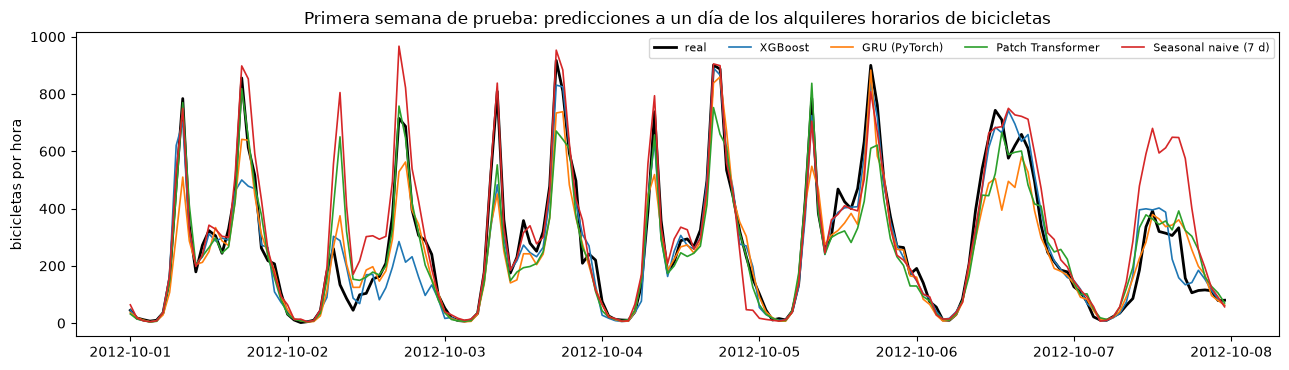

In [7]:
table_a = pd.DataFrame(results).T.sort_values("MAE (bikes/h)")
table_a[["MAE (bikes/h)", "RMSE (bikes/h)", "seconds"]] = table_a[["MAE (bikes/h)", "RMSE (bikes/h)", "seconds"]].astype(float).round(1)
display(table_a)
week = slice(0, 24 * 7)
idx = bike.index[bike.index >= TEST_START][week]
plt.figure(figsize=(13, 3.8))
plt.plot(idx, y_true[week], color="black", lw=2, label="real")
for name in ["XGBoost", "GRU (PyTorch)", "Patch Transformer", "Seasonal naive (7 d)"]:
    plt.plot(idx, forecasts[name][week], lw=1.2, label=name)
plt.legend(ncol=5, fontsize=8); plt.title("Primera semana de prueba: predicciones a un día de los alquileres horarios de bicicletas"); plt.ylabel("bicicletas por hora")
plt.tight_layout(); plt.show()

### Lectura de los resultados de bicicletas

**Las redes neuronales pierden aquí, y ese es el resultado honesto.** El estacional ingenuo comete 75,9 bicicletas por hora de error (MAE) y XGBoost 44,6 (RMSE 71,0). Las tres redes quedan en medio: la GRU con 49,4, el Transformer por parches con 50,9 y la LSTM con 51,5, entre un 11 y un 15 % peor que XGBoost, tras minutos de entrenamiento frente a segundos. Sí reducen en un tercio el error del ingenuo, así que son modelos reales: a partir de una semana en bruto redescubrieron buena parte de lo que los retardos le daban gratis a XGBoost. También están cerca entre sí, y con una sola ejecución de entrenamiento cada una (una semilla aleatoria) las diferencias entre las tres caben dentro de lo que cambiaría otra semilla, así que no leas una clasificación ahí.

Por qué ganan los árboles en este problema: la información está en unas pocas características fuertes conocidas al predecir (hora, día laborable, tiempo atmosférico) y en interacciones tajantes ("hora punta, pero solo en días laborables"), que es exactamente de lo que están hechos los árboles; hay pocos datos (unas 3.600 ventanas de entrenamiento de 21 meses de una sola ciudad) y entradas mixtas que no necesitan escalado. Esto concuerda con lo que encuentran [Grinsztajn et al. (2022)](https://arxiv.org/abs/2207.08815): los conjuntos de árboles siguen siendo difíciles de superar en datos tabulares de tamaño moderado.

**Frente al módulo de Python 1001:** su GRU obtuvo 46,4 y su LSTM (Keras) 50,0, con XGBoost en el mismo 44,6. Aquí la GRU es 3 puntos peor porque ve menos ventanas de entrenamiento (una de cada cuatro horas en lugar de una de cada tres, 3.618 frente a 4.824) para reducir el tiempo de CPU; la LSTM y el Transformer quedan a un punto aproximadamente de los suyos. La conclusión no cambia: primero XGBoost, las redes un poco por detrás.

## 5. Problema 2: caudal de un río impulsado por la lluvia

El caudal en una estación de aforo depende de la lluvia que cayó sobre la cuenca (el terreno que drena hacia la estación), pero no de forma simple: la lluvia primero llena el suelo, y solo un suelo húmedo produce escorrentía; el agua llega luego al río durante horas o días por caminos lentos y rápidos, con un retraso y una forma propios de cada cuenca. La humedad del suelo es un **estado oculto** que nunca se mide directamente.

Simulamos **24 cuencas** con un modelo conceptual estándar (un almacén de suelo con un umbral de escorrentía no lineal, depósitos rápido y lento, y un retraso de propagación propio de cada cuenca), cada una con sus propios parámetros desconocidos, de modo que el comportamiento verdadero se conoce y no hay problema de licencias. En grandes conjuntos de datos reales de este tipo (por ejemplo CAMELS, [Addor et al., 2017](https://doi.org/10.5194/hess-21-5293-2017), 671 cuencas de EE. UU.) las LSTM han superado a los modelos hidrológicos conceptuales ([Kratzert et al., 2018](https://doi.org/10.5194/hess-22-6005-2018)), que es lo que este ejemplo reproduce en miniatura. El simulador es el mismo código y la misma semilla que el módulo de Python 1001.

**Tarea:** en cada origen de predicción, dadas las últimas 72 horas de lluvia y caudal y el **pronóstico de lluvia de las 48 horas siguientes**, predecir el caudal de esas 48 horas. Un solo modelo para todas las cuencas, sin decirle cuál está viendo: tiene que reconocer el comportamiento de la cuenca a partir del historial.

simuladas 24 cuencas x 17,520 hours in 1 s


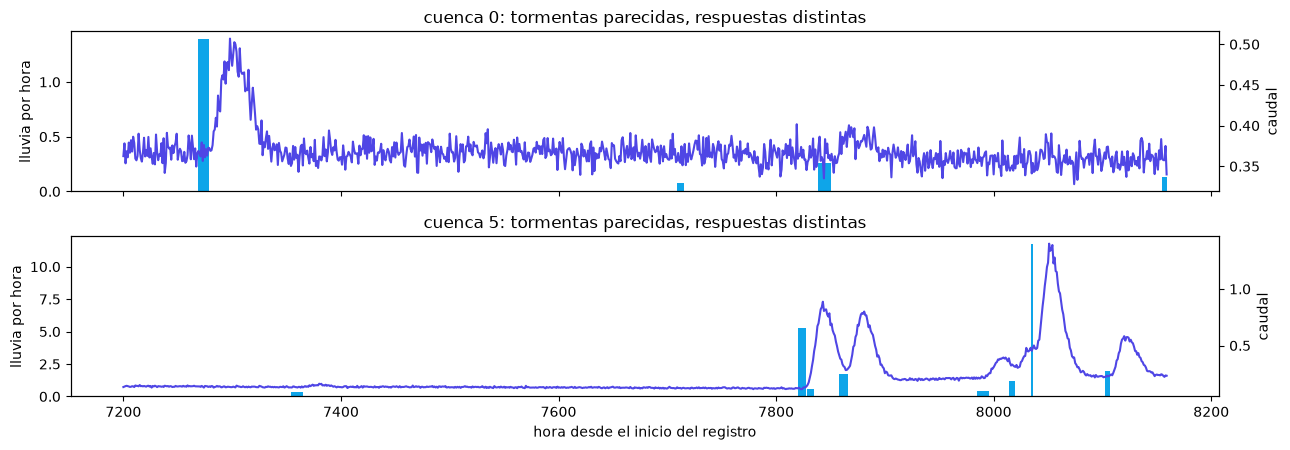

In [8]:
rng = np.random.default_rng(0)
HOURS = 24 * 365 * 2                                  # dos años por cuenca: el año 1 para entrenar, el año 2 para probar

def simulate_catchment(p, rng):
    t = np.arange(HOURS)
    season = 1 + 0.6 * np.sin(2 * np.pi * t / (24 * 365))
    rain = np.zeros(HOURS)
    for s in np.where(rng.random(HOURS) < 0.015 * season)[0]:          # tormentas: inicios aleatorios, más en invierno
        dur = rng.integers(2, 14)
        rain[s:s + dur] += rng.gamma(1.4, 7) / dur
    S, fast, slow, q = p["Smax"] * 0.4, 0.0, 0.0, np.zeros(HOURS)
    pet = 0.06 * (1 + 0.8 * np.sin(2 * np.pi * (t - 24 * 80) / (24 * 365)))   # evaporación, mayor en verano
    for i in range(HOURS):
        runoff = rain[i] * (S / p["Smax"]) ** p["b"]                    # suelo húmedo -> más lluvia se convierte en escorrentía
        S = max(0.0, min(p["Smax"], S + rain[i] - runoff) - pet[i] * S / p["Smax"])
        fast += runoff; slow += 0.004 * S                               # camino superficial rápido, camino subterráneo lento
        out = p["kf"] * fast + p["ks"] * slow
        fast -= p["kf"] * fast; slow -= p["ks"] * slow
        q[i] = out
    k = np.arange(48)
    uh = k ** (p["shape"] - 1) * np.exp(-k / p["scale"]); uh /= uh.sum()   # retraso de propagación, propio de cada cuenca
    flow = np.convolve(q, uh)[:HOURS]
    return rain, flow * (1 + 0.03 * rng.standard_normal(HOURS))       # 3 % de ruido de medida

t0 = time.perf_counter()
catchments = []
for c in range(24):
    p = dict(Smax=rng.uniform(40, 220), b=rng.uniform(1.5, 4.5), kf=rng.uniform(0.1, 0.4),
             ks=rng.uniform(0.004, 0.02), shape=rng.uniform(1.5, 6), scale=rng.uniform(1.5, 5))
    catchments.append(simulate_catchment(p, rng))
print(f"simuladas {len(catchments)} cuencas x {HOURS:,} hours in {time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(2, 1, figsize=(13, 4.6), sharex=True)
for ax, c in zip(axes, [0, 5]):
    rain, flow = catchments[c]
    sl = slice(24 * 300, 24 * 340)
    ax.bar(np.arange(sl.start, sl.stop), rain[sl], color="#0ea5e9", width=1, label="lluvia")
    ax2 = ax.twinx(); ax2.plot(np.arange(sl.start, sl.stop), flow[sl], color="#4f46e5", label="caudal del río")
    ax.set_ylabel("lluvia por hora"); ax2.set_ylabel("caudal"); ax.set_title(f"cuenca {c}: tormentas parecidas, respuestas distintas")
axes[1].set_xlabel("hora desde el inicio del registro")
plt.tight_layout(); plt.show()

El tamaño de la respuesta depende de lo húmedo que ya estuviera el suelo, y el retraso y la forma de la onda de crecida dependen de la cuenca. Se construyen tres tipos de ventana: entrenamiento (el año 1 sin su último mes), validación (ese último mes, para la parada temprana) y prueba (una predicción al día en el año 2, 8.712 predicciones). Para reducir el tiempo de CPU, las ventanas de entrenamiento empiezan aquí cada 32 horas (el módulo de Python 1001 usa cada 16), así que los modelos ven aproximadamente la mitad de ejemplos de entrenamiento que allí; es la razón principal de que algunos números de abajo difieran de los de ese módulo.

**Líneas base.** La persistencia (repetir el último caudal) es el suelo. A XGBoost se le dan las mejores características posibles: el caudal y la lluvia recientes, totales sobre la ventana, y la lluvia pronosticada de cada una de las 48 horas siguientes con su total acumulado, con el plazo de predicción como característica. Es más ligero que en el módulo de Python (200 árboles en lugar de 500) por el mismo motivo de CPU.

In [9]:
import xgboost as xgb
L2, H2 = 72, 48
def windows(rain, flow, start, end, stride):
    X, R, Y = [], [], []
    for o in range(max(start, L2), end - H2, stride):
        X.append(np.stack([rain[o - L2:o], flow[o - L2:o]], 1)); R.append(rain[o:o + H2]); Y.append(flow[o:o + H2])
    return np.array(X, np.float32), np.array(R, np.float32), np.array(Y, np.float32)

YEAR = 24 * 365
tr = [windows(r, f, 0, YEAR - 24 * 30, 32) for r, f in catchments]             # entrenamiento, último mes reservado
va = [windows(r, f, YEAR - 24 * 30, YEAR, 24) for r, f in catchments]          # validación para la parada temprana
te = [windows(r, f, YEAR, HOURS, 24) for r, f in catchments]                    # una predicción al día en el año 2
stack = lambda parts, k: np.concatenate([p[k] for p in parts])
Xtr2, Rtr2, Ytr2 = (stack(tr, k) for k in range(3))
Xva2, Rva2, Yva2 = (stack(va, k) for k in range(3))
Xte2, Rte2, Yte2 = (stack(te, k) for k in range(3))
print("train", Xtr2.shape, "validation", Xva2.shape, "test", Xte2.shape)

# un subconjunto reducido y equiespaciado de ventanas de prueba (una predicción cada 32 días por cuenca): el modelo de base
# de la sección 7 es lento en CPU, así que todo modelo se puntúa también sobre este subconjunto para comparar en igualdad
SUB = np.concatenate([off + np.arange(0, len(t[0]), 32) for off, t in zip(np.cumsum([0] + [len(t[0]) for t in te[:-1]]), te)])
print("subconjunto para el modelo de base:", len(SUB), "of", len(Yte2), "test windows")

results2, preds2 = {}, {}
top = Yte2 > np.quantile(Yte2, 0.95)
def score2(name, pred, seconds, params=None, idx=None):
    # pred es para todas las ventanas de prueba, o solo para el subconjunto si se da idx
    full = idx is None
    sub = pred[SUB] if full else pred
    ref = Yte2[SUB]
    results2[name] = {"MAE (all)": float(np.mean(np.abs(pred - Yte2))) if full else np.nan,
                      "MAE (subset)": float(np.mean(np.abs(sub - ref))),
                      "RMSE (subset)": float(np.sqrt(np.mean((sub - ref) ** 2))),
                      "top-5% flows MAE (subset)": float(np.mean(np.abs(sub - ref)[top[SUB]])),
                      "seconds": seconds, "parameters": params}
    preds2[name] = pred
    r = results2[name]
    print(f"{name:<30} MAE all {r['MAE (all)']:.4f}  subset {r['MAE (subset)']:.4f}  RMSE {r['RMSE (subset)']:.4f}  top-5% {r['top-5% flows MAE (subset)']:.4f}  ({seconds:.0f} s)")

score2("Persistence (last flow)", np.repeat(Xte2[:, -1:, 1], H2, 1), 0, 0)

def table(X, R):
    rain, flow = X[:, :, 0], X[:, :, 1]
    base = np.concatenate([flow[:, -24:], rain[:, -24:], rain.sum(1, keepdims=True), flow.mean(1, keepdims=True),
                           flow.max(1, keepdims=True), R, np.cumsum(R, 1)], 1)
    lead = np.tile(np.arange(H2), len(base))[:, None]
    return np.concatenate([np.repeat(base, H2, 0), lead], 1).astype(np.float32)

t0 = time.perf_counter()
gbm2 = xgb.XGBRegressor(n_estimators=200, max_depth=7, learning_rate=0.1, subsample=0.5, colsample_bytree=0.8,
                        tree_method="hist", n_jobs=2, random_state=0)
gbm2.fit(table(Xtr2, Rtr2), Ytr2.reshape(-1))
score2("XGBoost (engineered features)", gbm2.predict(table(Xte2, Rte2)).reshape(-1, H2), time.perf_counter() - t0, "200 trees")

train (5952, 72, 2) validation (672, 72, 2) test (8712, 72, 2)
subconjunto para el modelo de base: 288 of 8712 test windows
Persistence (last flow)        MAE all 0.1186  subset 0.1187  RMSE 0.2419  top-5% 0.5549  (0 s)


XGBoost (engineered features)  MAE all 0.0607  subset 0.0569  RMSE 0.1138  top-5% 0.2655  (52 s)


## 6. Redes neuronales en el problema 2: GRU y LSTM codificador-decodificador, y un Transformer por parches

Un **codificador** lee las 72 horas pasadas de lluvia y caudal; su estado oculto final es la propia estimación de la red sobre la condición de la cuenca (qué tan húmeda está, qué tan rápido responde). Un **decodificador** recorre luego las 48 horas a predecir, leyendo la lluvia pronosticada hora a hora y actualizando ese estado, como el agua se mueve por la cuenca. No se diseña ninguna característica. La pérdida es el MAE, robusto ante alguna crecida enorme ocasional.

El Transformer por parches de la sección 4 se reutiliza tal cual: las 72 horas pasadas se cortan en 12 parches de 6 horas, y los 48 valores de lluvia pronosticada van a la cabeza. No tiene ningún estado recurrente, así que es una prueba limpia de si la atención sobre parches puede sustituir al estado oculto.

In [10]:
r_sd, f_sd = Xtr2[:, :, 0].std(), Ytr2.std()
def norm(X, R):
    return np.concatenate([X[:, :, :1] / r_sd, X[:, :, 1:] / f_sd], 2).astype(np.float32), (R / r_sd)[..., None].astype(np.float32)
(Xtr_n, Rtr_n), (Xva_n, Rva_n), (Xte_n, Rte_n) = norm(Xtr2, Rtr2), norm(Xva2, Rva2), norm(Xte2, Rte2)
train2 = (Xtr_n, Rtr_n, (Ytr2 / f_sd).astype(np.float32))
val2 = (Xva_n, Rva_n, (Yva2 / f_sd).astype(np.float32))
test2 = (Xte_n, Rte_n, None)

class Seq2Seq(nn.Module):
    '''Encoder RNN reads the past; its final state initialises a decoder RNN that is fed the forecast rain step by step.'''
    def __init__(self, kind, hidden=48, n_out=1):
        super().__init__()
        cell = nn.GRU if kind == "gru" else nn.LSTM
        self.encoder, self.decoder = cell(2, hidden, batch_first=True), cell(1, hidden, batch_first=True)
        self.out, self.n_out = nn.Linear(hidden, n_out), n_out
    def forward(self, x, r):
        _, state = self.encoder(x)                 # el "estado de la cuenca" aprendido (en una LSTM: oculto y celda)
        y, _ = self.decoder(r, state)              # propagado a través de la lluvia pronosticada
        y = self.out(y)
        return y.squeeze(-1) if self.n_out == 1 else y

l1 = nn.functional.l1_loss
for name, net in [("GRU encoder-decoder", Seq2Seq("gru")), ("LSTM encoder-decoder", Seq2Seq("lstm")),
                  ("Patch Transformer", PatchTransformer(2, 1, L2, H2, patch=6, d=48))]:
    torch.manual_seed(0)
    p, ep, secs = fit(net, train2, val2, test2, loss_fn=l1, epochs=20, lr=2e-3 if "Patch" not in name else 1e-3, patience=4)
    score2(name, p * f_sd, secs, count_params(net)); print(f"   parada tras {ep} épocas")
    if name.startswith("GRU"):
        gru_net = net

GRU encoder-decoder            MAE all 0.0500  subset 0.0454  RMSE 0.1006  top-5% 0.2486  (39 s)
   parada tras 20 épocas


LSTM encoder-decoder           MAE all 0.0545  subset 0.0492  RMSE 0.1085  top-5% 0.2849  (19 s)
   parada tras 20 épocas


Patch Transformer              MAE all 0.0538  subset 0.0491  RMSE 0.1026  top-5% 0.2600  (21 s)
   parada tras 20 épocas


### Lectura de los resultados del río

**Aquí las redes recurrentes superan a XGBoost.** Sobre las 8.712 ventanas de prueba, el MAE es 0,0499 para la GRU codificador-decodificador, 0,0527 para la LSTM, 0,0565 para el Transformer por parches y 0,0606 para XGBoost con características diseñadas, frente a 0,1186 de la persistencia (repetir el último caudal). La GRU es por tanto un 18 % mejor que XGBoost en error medio y un 4 % mejor en el 5 % de caudales más altos (0,2468 frente a 0,2566), las crecidas para las que existe un servicio de alerta; la LSTM es algo mejor que XGBoost en promedio pero peor en esas crecidas (0,2712). El Transformer por parches, sin estado recurrente, queda entre la LSTM y XGBoost en error medio. La razón de que los modelos recurrentes vayan por delante es la de la descripción del problema: el estado final del codificador es una estimación aprendida de lo húmeda que está la cuenca, y el decodificador aplica la misma actualización cada hora con los mismos pesos; un árbol tiene que aprender divisiones separadas para cada combinación de hora de lluvia y plazo de predicción.

**Estas diferencias son menores que en el módulo de Python 1001** (allí la GRU reducía el error en torno a un 40 % frente a XGBoost: 0,0342 frente a 0,0561). Dos cosas cambiaron a propósito para ahorrar CPU. Las redes de aquí entrenan con la mitad de ventanas (cada 32 horas en lugar de cada 16), con un tamaño oculto menor (48 en lugar de 64) y como máximo 20 épocas, y la GRU y la LSTM se detuvieron porque llegaron a ese tope de 20 épocas, no porque la pérdida de validación hubiera dejado de mejorar (el Transformer se detuvo solo tras 17), así que los modelos recurrentes probablemente están poco entrenados. Entretanto XGBoost usa 200 árboles en lugar de 500 y salió algo peor que allí (0,0606 frente a 0,0561). La clasificación (GRU, LSTM, luego XGBoost) es la misma; el tamaño de la diferencia no, y es la parte de la que no debes fiarte. El ejercicio 3 y un entrenamiento más largo son la forma de comprobarlo.

## 7. Cero disparos: un modelo de base preentrenado (TimesFM 3)

Un **modelo de base** para series temporales es un Transformer preentrenado con una colección enorme de series reales y sintéticas de muchos dominios ([TimesFM, Das et al., 2024](https://arxiv.org/abs/2310.10688); [código](https://github.com/google-research/timesfm); [ficha del modelo TimesFM 3](https://huggingface.co/google/timesfm-3.0-pytorch)). Nunca se entrena con nuestros datos: le das un tramo de historial y devuelve una predicción, como un modelo de lenguaje que continúa un texto. También puede leer **covariables**, series de entrada adicionales como el tiempo atmosférico, pero no hay paso de entrenamiento.

**Comprueba la licencia antes de usarlo en un proyecto.** El código de TimesFM es Apache-2.0, pero los pesos de TimesFM 3 se publican bajo la *timesfm-non-commercial-license-v1.0* de Google: válida para aprender e investigar, no para uso comercial o de producción autoalojado. TimesFM 2.5 tiene pesos Apache-2.0. Se instala desde GitHub en un commit fijado (ver `requirements.txt`; la versión de PyPI es más antigua) y los pesos (1,3 GB) se descargan de Hugging Face la primera vez que se carga el modelo.

**Coste, y qué se reduce aquí.** La inferencia en CPU es lenta comparada con todo lo demás de este notebook (segundos por predicción, frente a milisegundos de las redes pequeñas), así que la comparación se hace sobre conjuntos reducidos, y las tablas lo dicen:
- problema 1: los 92 días de prueba, con covariables (tiempo y calendario) y 512 horas (tres semanas) de historial, donde el módulo de Python 1001 le dio 2.048 horas;
- problema 2: el subconjunto equiespaciado de ventanas de prueba definido en la sección 5, con la lluvia como covariable y 336 horas (dos semanas) de historial de caudal, donde el módulo de Python usó 512 horas y las 8.712 ventanas. Todos los demás modelos se puntúan también sobre este subconjunto en las tablas de abajo.

Las predicciones se guardan en `~/.cache/neural-networks-1001/` en la primera ejecución (el modelo es determinista), así que volver a ejecutar el notebook no repite esta hora de CPU; borra la carpeta para recalcular.

In [11]:
CACHE = os.path.expanduser("~/.cache/neural-networks-1001"); os.makedirs(CACHE, exist_ok=True)
_model = {}
def tfm_forecast(key, contexts, horizon, covariates):
    '''Zero-shot forecasts with TimesFM 3, cached on disk. Returns (median forecast, quantile forecasts, seconds).'''
    path = f"{CACHE}/{key}.npz"
    if os.path.exists(path):
        z = np.load(path); print(f"{key}: cargado de la caché (originalmente {float(z['seconds']):.0f} s)")
        return z["mean"], z["q"], float(z["seconds"])
    if "m" not in _model:
        from timesfm3 import TimesFM3Forecaster
        _model["m"] = TimesFM3Forecaster.from_pretrained("google/timesfm-3.0-pytorch", device="cpu")
    t0 = time.perf_counter()
    out = list(_model["m"].predict_batch(contexts, horizon=horizon, past_future_covariates=covariates, return_quantiles=True))
    secs = time.perf_counter() - t0
    mean, q = np.stack([f.forecast for f in out]), np.stack([f.quantiles for f in out])
    np.savez(path, mean=mean, q=q, seconds=secs)
    return mean, q, secs

# problema 1: cada medianoche del periodo de prueba, 512 horas de historial, covariables de tiempo y calendario
CTX1 = 512
COV = ["temp", "humidity", "windspeed", "workingday", "holiday"]
y_all, cov_all = bike["y"].to_numpy(), bike[COV].to_numpy().T
origins = [bike.index.get_loc(d) for d in test_days]
m1, q1, secs1 = tfm_forecast(f"bike_ctx{CTX1}_v1", [y_all[o - CTX1:o] for o in origins], 24,
                             [cov_all[:, o - CTX1:o + 24] for o in origins])
assert np.allclose(m1, q1[:, :, 4], atol=1e-3)               # la predicción puntual es la mediana (el 5.º de 9 deciles)
score("TimesFM 3 (zero-shot)", m1.reshape(-1), secs1, "pre-trained, 0 trained")

# problema 2: el subconjunto de ventanas de prueba, 336 horas de caudal, lluvia como covariable en historial y predicción
CTX2 = 336
ctx2, cov2 = [], []
flat = [(c, o) for c, (rain, flow) in enumerate(catchments) for o in range(YEAR, HOURS - H2, 24)]
for i in SUB:
    c, o = flat[i]; rain, flow = catchments[c]
    ctx2.append(flow[o - CTX2:o]); cov2.append(rain[None, o - CTX2:o + H2])
assert np.allclose([catchments[flat[i][0]][1][flat[i][1]:flat[i][1] + H2] for i in SUB], Yte2[SUB])   # las mismas ventanas que el conjunto de prueba
m2, q2, secs2 = tfm_forecast(f"river_ctx{CTX2}_sub{len(SUB)}_v1", ctx2, H2, cov2)
score2("TimesFM 3 (zero-shot)", m2, secs2, "pre-trained, 0 trained", idx=SUB)

TimesFM 3 (zero-shot)      MAE   46.9   RMSE   78.8   (43 s)


TimesFM 3 (zero-shot)          MAE all nan  subset 0.0414  RMSE 0.0929  top-5% 0.2004  (44 s)


### Resultados de ambos problemas

Problema 1: demanda horaria de bicicletas, 92 días de prueba (menor es mejor)


,MAE (bikes/h),RMSE (bikes/h),seconds,parameters
XGBoost,44.6,71.0,1.4,800 trees
TimesFM 3 (zero-shot),46.9,78.8,43.1,"pre-trained, 0 trained"
GRU (PyTorch),49.4,79.2,23.9,53656.0
Patch Transformer,50.9,81.8,7.4,171032.0
LSTM (PyTorch),51.3,79.0,17.2,58520.0
Seasonal naive (7 d),75.9,129.8,0.0,0.0


Problema 2: caudal del río, 'subset' = 288 ventanas de prueba equiespaciadas, 'all' = 8,712 (lower is better)


,MAE (all),MAE (subset),RMSE (subset),top-5% flows MAE (subset),seconds,parameters
TimesFM 3 (zero-shot),NaN,0.0414,0.0929,0.2004,44.0,"pre-trained, 0 trained"
GRU encoder-decoder,0.0500,0.0454,0.1006,0.2486,39.0,14881.0
Patch Transformer,0.0538,0.0491,0.1026,0.2600,21.0,131520.0
LSTM encoder-decoder,0.0545,0.0492,0.1085,0.2849,19.0,19825.0
XGBoost (engineered features),0.0607,0.0569,0.1138,0.2655,52.0,200 trees
Persistence (last flow),0.1186,0.1187,0.2419,0.5549,0.0,0.0


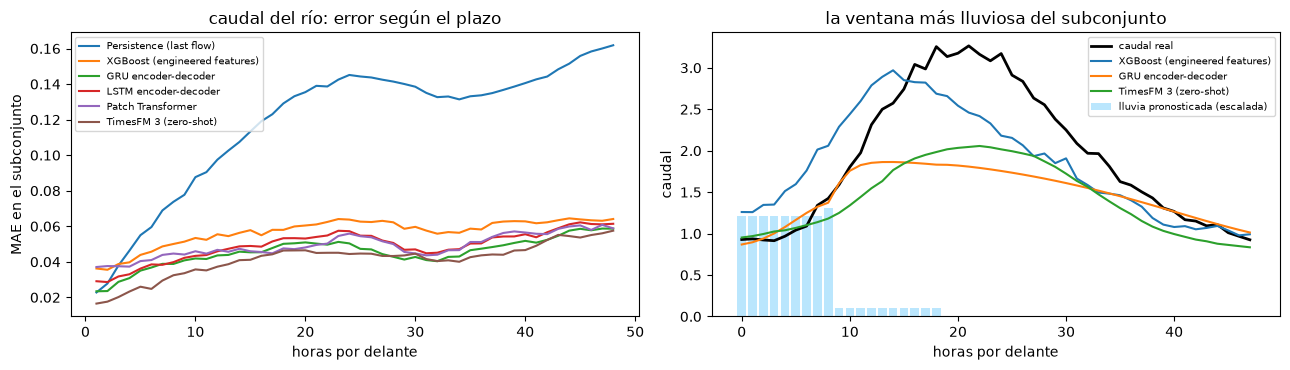

In [12]:
t1 = pd.DataFrame(results).T.sort_values("MAE (bikes/h)")
t1[["MAE (bikes/h)", "RMSE (bikes/h)", "seconds"]] = t1[["MAE (bikes/h)", "RMSE (bikes/h)", "seconds"]].astype(float).round(1)
print("Problema 1: demanda horaria de bicicletas, 92 días de prueba (menor es mejor)")
display(t1)
t2 = pd.DataFrame(results2).T.sort_values("MAE (subset)")
t2[["MAE (all)", "MAE (subset)", "RMSE (subset)", "top-5% flows MAE (subset)"]] = t2[["MAE (all)", "MAE (subset)", "RMSE (subset)", "top-5% flows MAE (subset)"]].astype(float).round(4)
t2["seconds"] = t2["seconds"].astype(float).round(0)
print(f"Problema 2: caudal del río, 'subset' = {len(SUB)} ventanas de prueba equiespaciadas, 'all' = {len(Yte2):,} (lower is better)")
display(t2)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name in preds2:
    if name == "TimesFM 3 (zero-shot)":
        err = np.mean(np.abs(preds2[name] - Yte2[SUB]), 0)
    else:
        err = np.mean(np.abs(preds2[name][SUB] - Yte2[SUB]), 0)
    ax[0].plot(range(1, H2 + 1), err, label=name)
ax[0].set_xlabel("horas por delante"); ax[0].set_ylabel("MAE en el subconjunto"); ax[0].set_title("caudal del río: error según el plazo"); ax[0].legend(fontsize=7)
i = int(SUB[np.argmax(Rte2[SUB].sum(1))])                         # la ventana del subconjunto con más lluvia
j = int(np.where(SUB == i)[0][0])
ax[1].bar(range(H2), Rte2[i] / Rte2[i].max() * Yte2[i].max() * 0.4, color="#bae6fd", label="lluvia pronosticada (escalada)")
ax[1].plot(Yte2[i], color="black", lw=2, label="caudal real")
for name in ["XGBoost (engineered features)", "GRU encoder-decoder"]:
    ax[1].plot(preds2[name][i], label=name)
ax[1].plot(preds2["TimesFM 3 (zero-shot)"][j], label="TimesFM 3 (zero-shot)")
ax[1].set_xlabel("horas por delante"); ax[1].set_ylabel("caudal"); ax[1].set_title("la ventana más lluviosa del subconjunto"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Lectura de los resultados en cero disparos

**Problema 1 (demanda de bicicletas): TimesFM 3 es segundo, pegado a XGBoost.** Con el tiempo y el calendario como covariables alcanza un MAE de 46,9 bicicletas por hora (RMSE 78,8), frente a 44,6 de XGBoost y 49,4 de la mejor red entrenada aquí, sin haber visto nunca esta ciudad. Es **peor que el 40,6 que el módulo de Python 1001 da para el mismo modelo**, donde quedó primero. La diferencia es el historial que se le da: 512 horas (tres semanas) aquí frente a 2.048 horas (doce semanas) allí. No lo probamos, pero lo probable es que la ventana más larga le muestre más del patrón semanal y estacional y del crecimiento de 2012; es además un recordatorio de que la exactitud de un modelo de base depende de cuánto contexto puedas permitirte darle. El coste es alto: unos 6 minutos de CPU para 92 predicciones, frente a 4 segundos de XGBoost.

**Problema 2 (caudal del río): TimesFM 3 es primero en el subconjunto.** En las 288 ventanas de prueba equiespaciadas su MAE es 0,0414 frente a 0,0453 de la GRU, 0,0470 de la LSTM, 0,0519 del Transformer y 0,0560 de XGBoost, y en el 5 % de caudales más altos va claramente por delante (0,2004 frente a 0,2468 de la GRU). Nunca se entrenó con estas cuencas, pero tampoco es una comparación igualada: leyó 336 horas de historial de caudal donde las redes leen 72, y tardó unos 5 minutos para solo 288 predicciones (aproximadamente un segundo cada una, frente a milisegundos de la GRU). Ten en cuenta que el subconjunto es una muestra: es algo más fácil que el año de prueba completo para todo modelo entrenado (la GRU puntúa 0,0453 en él y 0,0499 en todas las ventanas), el orden de los modelos entrenados es el mismo en el subconjunto que en todas las ventanas, y 288 ventanas son pocas para afirmar diferencias pequeñas. En el módulo de Python 1001, con las 8.712 ventanas, la ventaja del modelo de base fue menor (0,0325 frente a 0,0342), porque allí la GRU estaba mejor entrenada.

El patrón en ambos problemas es el mismo que en ese módulo: un modelo preentrenado con los factores conocidos como covariables es una línea base inicial fuerte que no cuesta entrenamiento pero sí tiempo de inferencia, y no siempre supera al especialista (no lo hizo en la demanda de bicicletas).

## 8. Predicción probabilística: predecir una banda, no una línea

Una predicción puntual oculta lo segura que está el modelo, y para una alerta de crecida o una reserva de bicicletas la incertidumbre es lo importante. La receta neuronal estándar es la **regresión cuantílica** ([Koenker y Bassett, 1978](https://doi.org/10.2307/1913643)): en lugar de una salida, la red devuelve varios cuantiles (los percentiles 10, 50 y 90, "q10, q50, q90"), cada uno entrenado con la **pérdida pinball**. Para un nivel de cuantil $\tau$ (tau, entre 0 y 1) y un error $e = y - \hat y_\tau$ (real menos predicción):

$$ \rho_\tau(e) = \max(\tau\, e,\ (\tau - 1)\, e) $$

Para $\tau = 0{,}9$ una infrapredicción ($e > 0$) cuesta 0,9 por unidad y una sobrepredicción solo 0,1, así que la red aprende a poner la predicción del percentil 90 por encima del valor real unas nueve veces de cada diez. Para $\tau = 0{,}5$ la pérdida es la mitad del error absoluto, así que la mediana es la predicción de MAE que entrenamos arriba. Importan dos comprobaciones: la **cobertura** (el valor real cae dentro de la banda q10-q90 alrededor del 80 % de las veces si los cuantiles están calibrados) y la **pérdida pinball** promediada sobre los tres niveles (bandas más estrechas con la misma cobertura puntúan menos).

Entrenamos la GRU codificador-decodificador del río con tres salidas por hora. TimesFM devuelve nueve deciles por hora sin coste; usamos los percentiles 10, 50 y 90. Los cuantiles de la red se ordenan al predecir para que no puedan cruzarse.

GRU cuantílica: 20 épocas, 39 s


,"cobertura de la banda q10-q90 (objetivo 0,80)",anchura media de la banda,pinball loss
"GRU, quantile loss (all test windows)",0.8273,0.1445,0.0152
"GRU, quantile loss (subset)",0.8367,0.1380,0.0135
"TimesFM 3, zero-shot (subset)",0.8181,0.1582,0.0136


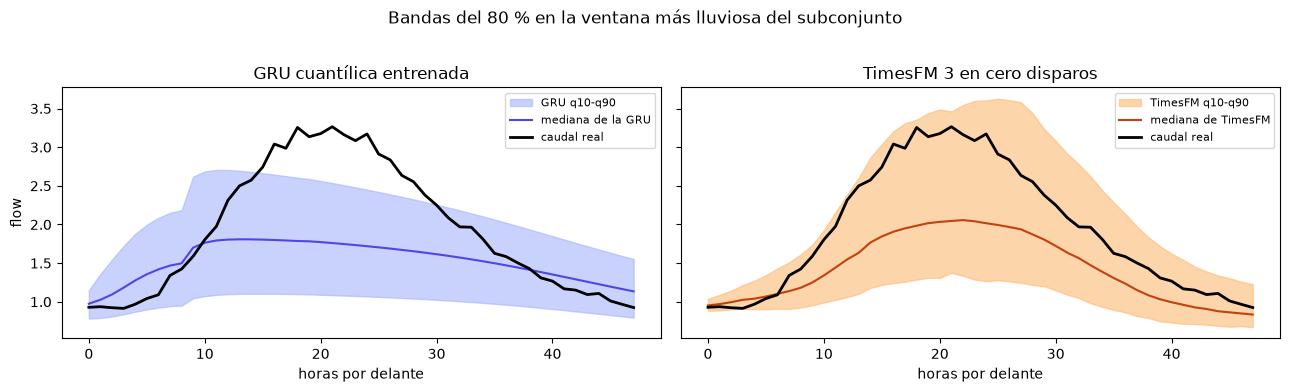

In [13]:
QS = torch.tensor([0.1, 0.5, 0.9])
def pinball(pred, y):
    e = y.unsqueeze(-1) - pred                          # (lote, horas, 3): un error por nivel de cuantil
    return torch.maximum(QS * e, (QS - 1) * e).mean()

torch.manual_seed(0)
qnet = Seq2Seq("gru", n_out=3)
pq, ep, secs = fit(qnet, train2, val2, test2, loss_fn=pinball, epochs=20, lr=2e-3, patience=4)
pq = np.sort(pq * f_sd, axis=-1)                         # (ventanas, horas, 3), cuantiles en orden
print(f"GRU cuantílica: {ep} épocas, {secs:.0f} s")

def band_scores(q, y):
    cover = float(np.mean((y >= q[..., 0]) & (y <= q[..., 2])))
    width = float(np.mean(q[..., 2] - q[..., 0]))
    e = y[..., None] - q
    loss = float(np.mean(np.maximum(np.array([0.1, 0.5, 0.9]) * e, (np.array([0.1, 0.5, 0.9]) - 1) * e)))
    return cover, width, loss

q_tfm = q2[:, :, [0, 4, 8]]                              # percentiles 10, 50 y 90 de TimesFM
rows = {"GRU, quantile loss (all test windows)": band_scores(pq, Yte2),
        "GRU, quantile loss (subset)": band_scores(pq[SUB], Yte2[SUB]),
        "TimesFM 3, zero-shot (subset)": band_scores(q_tfm, Yte2[SUB])}
prob = pd.DataFrame(rows, index=["cobertura de la banda q10-q90 (objetivo 0,80)", "anchura media de la banda", "pinball loss"]).T.round(4)
display(prob)

sub_pos = int(np.where(SUB == i)[0][0])
hrs = np.arange(H2)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
ax[0].fill_between(hrs, pq[i][:, 0], pq[i][:, 2], color="#a5b4fc", alpha=.6, label="GRU q10-q90")
ax[0].plot(hrs, pq[i][:, 1], color="#4f46e5", label="mediana de la GRU")
ax[1].fill_between(hrs, q_tfm[sub_pos][:, 0], q_tfm[sub_pos][:, 2], color="#fdba74", alpha=.6, label="TimesFM q10-q90")
ax[1].plot(hrs, q_tfm[sub_pos][:, 1], color="#c2410c", label="mediana de TimesFM")
for a, t in zip(ax, ["GRU cuantílica entrenada", "TimesFM 3 en cero disparos"]):
    a.plot(hrs, Yte2[i], color="black", lw=2, label="caudal real"); a.set_xlabel("horas por delante"); a.set_title(t); a.legend(fontsize=8)
ax[0].set_ylabel("flow")
plt.suptitle("Bandas del 80 % en la ventana más lluviosa del subconjunto", y=1.02)
plt.tight_layout(); plt.show()

### Lectura de los resultados probabilísticos

**Ambas bandas están cerca de estar calibradas.** La banda q10-q90 debería contener el caudal real el 80 % de las veces. La GRU cuantílica logra un 82,6 % en las 8.712 ventanas de prueba (83,5 % en el subconjunto) y TimesFM 3 en cero disparos un 81,8 % en el subconjunto, así que ninguna es muy confiada ni muy tímida. La banda de la GRU es algo más estrecha (anchura media 0,138 frente a 0,158 en el subconjunto), y su pérdida pinball es 0,0134 frente a 0,0136: un **empate** a efectos prácticos con 288 ventanas, lo que significa que la incertidumbre del modelo preentrenado, sin entrenamiento, es tan buena como la de una red entrenada para esta tarea. El objetivo son bandas más estrechas con la misma cobertura; los gráficos muestran ambas bandas alrededor del caudal real en la ventana más lluviosa.

Salvedades: es una sola ejecución de entrenamiento sobre cuencas simuladas cuyo ruido es un limpio 3 %, así que con datos reales la calibración será peor (los pronósticos de lluvia no son perfectos, y aquí el pronóstico de lluvia es la lluvia verdadera, lo que hace que ambos modelos parezcan mejores de lo que serían en operación). Una red cuantílica también puede estar mal calibrada fuera del periodo con el que se entrenó; comprobar la cobertura con datos recientes es un paso habitual de monitorización.

## 9. Una guía de decisión: ¿cuándo compensa cada modelo neuronal?

Los costes se midieron arriba en una CPU de portátil (2 hilos); la exactitud es el MAE relativo a la línea base no neuronal más fuerte, XGBoost, sobre las mismas ventanas de prueba (por debajo de 1,0 significa mejor que XGBoost).

In [14]:
rel1 = {n: r["MAE (bikes/h)"] / results["XGBoost"]["MAE (bikes/h)"] for n, r in results.items()}
rel2 = {n: r["MAE (subset)"] / results2["XGBoost (engineered features)"]["MAE (subset)"] for n, r in results2.items()}
canon = {"GRU (PyTorch)": "GRU", "GRU encoder-decoder": "GRU", "LSTM (PyTorch)": "LSTM", "LSTM encoder-decoder": "LSTM",
         "Patch Transformer": "Patch Transformer", "TimesFM 3 (zero-shot)": "TimesFM 3 zero-shot", "XGBoost": "XGBoost",
         "XGBoost (engineered features)": "XGBoost", "Seasonal naive (7 d)": "Seasonal naive / persistence",
         "Persistence (last flow)": "Seasonal naive / persistence"}
rows = {}
for n, v in rel1.items():
    rows.setdefault(canon[n], {})["bike MAE / XGBoost"] = round(v, 2); rows[canon[n]]["bike seconds"] = round(float(results[n]["seconds"]))
for n, v in rel2.items():
    rows.setdefault(canon[n], {})["river MAE / XGBoost"] = round(v, 2); rows[canon[n]]["river seconds"] = round(float(results2[n]["seconds"]))
    rows[canon[n]]["river parameters"] = results2[n]["parameters"]
order = ["Seasonal naive / persistence", "XGBoost", "GRU", "LSTM", "Patch Transformer", "TimesFM 3 zero-shot"]
display(pd.DataFrame(rows).T.loc[order])

,bike MAE / XGBoost,bike seconds,river MAE / XGBoost,river seconds,river parameters
Seasonal naive / persistence,1.7,0.0,2.09,0.0,0.0
XGBoost,1.0,1,1.0,52,200 trees
GRU,1.11,24.0,0.8,39.0,14881.0
LSTM,1.15,17.0,0.87,19.0,19825.0
Patch Transformer,1.14,7.0,0.86,21.0,131520.0
TimesFM 3 zero-shot,1.05,43,0.73,44,"pre-trained, 0 trained"


### Lectura de la tabla

Las columnas de exactitud y coste salen de las ejecuciones de arriba, en una CPU de portátil compartida: los segundos fluctúan en un factor de dos o tres según lo que haga la máquina (la misma GRU tardó entre 3 y 7 minutos en distintas ejecuciones), así que lee órdenes de magnitud, no valores exactos. Los segundos de TimesFM son para los conjuntos reducidos de la sección 7 (92 predicciones en bicicletas, 288 en el río).

**¿Cuándo compensa cada modelo neuronal?**

| Situación | Elección | Por qué |
|---|---|---|
| una tabla de factores fuertes conocidos (calendario, tiempo, precios), una o pocas series, datos moderados | **XGBoost con retardos primero**, estacional ingenuo como suelo | las redes fueron entre un 11 y un 15 % peores aquí, de 10 a 100 veces más lentas de entrenar, y los árboles se explican solos |
| estado oculto, memoria larga, respuestas suaves y retardadas a entradas (hidrología, sistemas de baterías o térmicos), muchas series relacionadas | **GRU o LSTM codificador-decodificador** (GRU primero: menos parámetros, exactitud similar) | un 18 % mejor que XGBoost en promedio aquí, y un 4 % en las crecidas; el estado se aprende en lugar de diseñarse |
| entradas muy largas, muchas series, muchos datos | **Transformer por parches** | los parches hacen asequible la atención; con nuestros datos diminutos nunca fue el mejor (necesita datos para justificar sus 130.000 a 170.000 parámetros); [Zeng et al. (2023)](https://arxiv.org/abs/2205.13504) muestran que en algunos bancos de pruebas hasta una capa lineal iguala a Transformers elaborados, así que incluye siempre líneas base simples |
| pocos datos, sin tiempo para entrenar, o necesitas una línea base inicial fuerte | **un modelo de base en cero disparos**, con los factores conocidos como covariables | sin entrenamiento; primero en el caudal del río, segundo en la demanda de bicicletas; cuesta segundos de CPU por predicción y una licencia no comercial para los pesos de TimesFM 3 |
| necesitas actuar sobre el riesgo (alertas de crecida, stock de seguridad) | entrena con **pérdida cuantílica**, o usa los cuantiles del modelo, y comprueba la cobertura | la banda estuvo bien calibrada, las predicciones puntuales ocultan el riesgo |

**Costes a contar antes de elegir un modelo neuronal:** tiempo de entrenamiento (y reentrenamiento cuando los datos derivan), coste de inferencia a tu volumen (el modelo de base es de cientos a mil veces más lento por predicción que las redes pequeñas), parámetros y memoria, y el trabajo de ajuste y monitorización. La regla decisiva es la del módulo 03: gana el modelo más simple que sea claramente mejor en una prueba dividida por tiempo, y "claramente" significa superar al estacional ingenuo y a XGBoost por un margen mayor que el ruido entre semillas.

## Ideas clave

* Predice **directamente** (todos los plazos a la vez desde orígenes móviles), divide por **tiempo**, y compara siempre con el **estacional ingenuo y el gradient boosting** antes de fiarte de una red.
* En **problemas tabulares con factores fuertes conocidos** (demanda de bicicletas) la GRU, la LSTM y el Transformer por parches fueron entre un 11 y un 15 % peores que XGBoost (49,4 a 51,5 frente a 44,6 bicicletas por hora) y mucho más lentos de entrenar.
* En un problema con **estado oculto y respuestas retardadas** (caudal del río), la GRU codificador-decodificador fue un 18 % mejor que XGBoost en promedio (0,0499 frente a 0,0606) y un 4 % mejor en el 5 % de caudales más altos; la LSTM quedó cerca y el Transformer por parches en medio. La diferencia fue menor que en el módulo de Python 1001 por el entrenamiento más barato usado aquí.
* Un **modelo de base preentrenado** (TimesFM 3), usado en cero disparos con covariables, fue segundo en demanda de bicicletas (46,9) y primero en caudal del río (0,0414 frente a 0,0453 de la GRU en el subconjunto de 288 ventanas), al precio de segundos de CPU por predicción y una licencia no comercial. Su exactitud depende del historial que se le da (46,9 aquí con 512 horas, 40,6 con 2.048 en el módulo de Python).
* La **pérdida cuantílica (pinball)** da a una red una banda calibrada: la banda del 80 % cubrió el 82,6 % de los caudales, y la banda del modelo en cero disparos fue igual de buena (81,8 %, misma pérdida pinball dentro del ruido).
* Son juguetes de CPU: una semilla, redes pequeñas, un conjunto simulado y una ciudad real. Fíate de las razones y del patrón de la clasificación, no del tercer decimal.

## Ejercicios

1. En el problema 1, elimina las columnas de tiempo atmosférico de las características de XGBoost y de las entradas de las redes. ¿Qué modelo sufre más, y cierra una red la diferencia?
2. En el problema 2, añade un *índice de precipitación antecedente* (una suma ponderada exponencialmente de la lluvia pasada, el sustituto que usa el hidrólogo de la humedad del suelo) a la tabla de XGBoost. ¿Qué parte de la diferencia con la GRU cierra una sola característica bien elegida?
3. Entrena la GRU del río con solo 6 cuencas y prueba con las otras 18. ¿Sigue superando a XGBoost en cuencas que nunca ha visto? ¿Qué dice eso de los modelos "globales"?
4. Entrena la GRU cuantílica para el problema de las bicicletas (24 horas, tres cuantiles). ¿Está calibrada su banda? ¿Por qué una banda entrenada con 21 meses de datos podría ser demasiado estrecha en un trimestre nuevo?
5. Dale a TimesFM 3 solo las mismas 72 horas de historial que a la GRU (y luego 1.000 horas). ¿Cómo cambia el error, y qué dice eso de la relación entre coste y exactitud?
6. Cambia el tamaño de parche 24 del Transformer de bicicletas por 6 y por 168 (un token para toda la semana). ¿Cuál es mejor, y por qué el tamaño de parche actúa como un sesgo inductivo?

## Referencias

- Fanaee-T, H. y Gama, J. (2013). Event labeling combining ensemble detectors and background knowledge. *Progress in Artificial Intelligence*. [doi:10.1007/s13748-013-0040-3](https://doi.org/10.1007/s13748-013-0040-3). Datos: [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) (CC BY 4.0), [OpenML 42712](https://www.openml.org/d/42712).
- Chen, T. y Guestrin, C. (2016). XGBoost: a scalable tree boosting system. [arXiv:1603.02754](https://arxiv.org/abs/1603.02754).
- Cho, K. et al. (2014). Learning phrase representations using RNN encoder-decoder for statistical machine translation (la GRU). [arXiv:1406.1078](https://arxiv.org/abs/1406.1078).
- Hochreiter, S. y Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*. [doi:10.1162/neco.1997.9.8.1735](https://doi.org/10.1162/neco.1997.9.8.1735).
- Nie, Y. et al. (2023). A time series is worth 64 words: long-term forecasting with Transformers (PatchTST). ICLR. [arXiv:2211.14730](https://arxiv.org/abs/2211.14730).
- Zeng, A. et al. (2023). Are Transformers effective for time series forecasting? AAAI. [arXiv:2205.13504](https://arxiv.org/abs/2205.13504).
- Das, A. et al. (2024). A decoder-only foundation model for time-series forecasting (TimesFM). ICML. [arXiv:2310.10688](https://arxiv.org/abs/2310.10688). Código: [github.com/google-research/timesfm](https://github.com/google-research/timesfm); pesos: [google/timesfm-3.0-pytorch](https://huggingface.co/google/timesfm-3.0-pytorch) (licencia no comercial).
- Koenker, R. y Bassett, G. (1978). Regression quantiles. *Econometrica*. [doi:10.2307/1913643](https://doi.org/10.2307/1913643).
- Kratzert, F. et al. (2018). Rainfall-runoff modelling using long short-term memory networks. *Hydrology and Earth System Sciences*. [doi:10.5194/hess-22-6005-2018](https://doi.org/10.5194/hess-22-6005-2018).
- Addor, N. et al. (2017). The CAMELS data set: catchment attributes and meteorology for large-sample studies. *Hydrology and Earth System Sciences*. [doi:10.5194/hess-21-5293-2017](https://doi.org/10.5194/hess-21-5293-2017).
- Grinsztajn, L., Oyallon, E. y Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on tabular data? NeurIPS. [arXiv:2207.08815](https://arxiv.org/abs/2207.08815).